In [1]:
import pandas as pd
import numpy as np
import seaborn as sns 
from datetime import datetime, timedelta

## Generating Dataset

In [2]:


# Set random seed for reproducibility
np.random.seed(42)

# Generate 1,500 rows of server logs
n_samples = 1500

# 1. Generate Timestamps over the last 3 months
start_date = datetime(2026, 8, 1)
date_list = [start_date + timedelta(minutes=int(i * 90)) for i in range(n_samples)]

# 2. Base Features
cpu_utilization = np.random.uniform(5, 95, n_samples)  # 5% to 95%
memory_utilization = cpu_utilization * 0.8 + np.random.normal(10, 5, n_samples) # correlated with CPU
memory_utilization = np.clip(memory_utilization, 10, 98)

network_traffic_gb = np.random.exponential(scale=15, size=n_samples) # right-skewed traffic
server_generation = np.random.choice(['Legacy', 'Current', 'Next-Gen'], size=n_samples, p=[0.2, 0.6, 0.2])

# 3. Target Variable: Power Consumption (kWh) with complex relationships
# Next-Gen is efficient (1.0x), Current is standard (1.5x), Legacy hogs power (2.5x)
gen_modifier = np.select(
    [server_generation == 'Next-Gen', server_generation == 'Current', server_generation == 'Legacy'],
    [1.0, 1.5, 2.5]
)

# Linear relationship + noise + structural impact
power_kwh = (cpu_utilization * 1.2) + (memory_utilization * 0.5) + (network_traffic_gb * 0.3)
power_kwh = power_kwh * gen_modifier + np.random.normal(15, 4, n_samples)

# 4. Inject real-world messiness (NaNs and Outliers)
# Add missing values to Memory Utilization (simulating sensor drops)
nan_indices = np.random.choice(n_samples, size=45, replace=False)
memory_utilization[nan_indices] = np.nan

# Add massive power outliers (simulating short-circuit spikes or faulty logs)
outlier_indices = np.random.choice(n_samples, size=10, replace=False)
power_kwh[outlier_indices] = power_kwh[outlier_indices] * 5

# Create DataFrame
df = pd.DataFrame({
    'timestamp': date_list,
    'cpu_utilization_pct': cpu_utilization,
    'memory_utilization_pct': memory_utilization,
    'network_traffic_gb': network_traffic_gb,
    'hardware_generation': server_generation,
    'power_consumption_kwh': power_kwh
})

# Save to CSV
df.to_csv('cloud_server_metrics.csv', index=False)
print("✅ Dataset 'cloud_server_metrics.csv' generated successfully with 1,500 records!")


✅ Dataset 'cloud_server_metrics.csv' generated successfully with 1,500 records!


In [3]:
df.head()
df.shape

(1500, 6)

In [4]:
df.describe()
## outliers detected in Power_consumption_kwh column

,timestamp,cpu_utilization_pct,memory_utilization_pct,network_traffic_gb,power_consumption_kwh
count,1500,1500.000000,1455.000000,1500.000000,1500.000000
mean,2026-09-16 20:15:00,49.942137,50.158602,14.755080,163.542433
min,2026-08-01 00:00:00,5.416882,10.000000,0.000461,22.419407
25%,2026-08-24 10:07:30,26.378954,31.209917,4.125901,90.060615
50%,2026-09-16 20:15:00,50.590557,50.347102,10.028280,149.635200
75%,2026-10-10 06:22:30,72.830242,69.064838,20.381705,213.525823
max,2026-11-02 16:30:00,94.974591,96.108474,115.852943,1764.792225
std,NaN,26.461356,21.866908,15.103911,108.107709


In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1500 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   timestamp               1500 non-null   datetime64[us]
 1   cpu_utilization_pct     1500 non-null   float64       
 2   memory_utilization_pct  1455 non-null   float64       
 3   network_traffic_gb      1500 non-null   float64       
 4   hardware_generation     1500 non-null   str           
 5   power_consumption_kwh   1500 non-null   float64       
dtypes: datetime64[us](1), float64(4), str(1)
memory usage: 80.7 KB


## removing outliers 

In [6]:
Q1=np.percentile(df['power_consumption_kwh'],25)
Q3=np.percentile(df['power_consumption_kwh'],75)
print(Q1 ,Q3)
IQR=Q3-Q1
minthres=Q1-1.5*IQR
maxthres=Q3+1.5*IQR
print(minthres,maxthres)

90.06061500292937 213.52582306240808
-95.13719708628871 398.7236351516261


In [7]:
df=df[(df['power_consumption_kwh'] >= minthres)  &  (df['power_consumption_kwh']<= maxthres)]
df.shape

(1468, 6)

## Handle missing Values 

In [8]:
## checking for null values 
print(df.isnull().sum())

timestamp                  0
cpu_utilization_pct        0
memory_utilization_pct    44
network_traffic_gb         0
hardware_generation        0
power_consumption_kwh      0
dtype: int64


In [9]:
## fill with median as it had outliers mean is not a great idea
memory_median = df['memory_utilization_pct'].median()
df['memory_utilization_pct']=df['memory_utilization_pct'].fillna(memory_median)
# print(df.isnull().sum())

In [10]:
print(df.isnull().sum())

timestamp                 0
cpu_utilization_pct       0
memory_utilization_pct    0
network_traffic_gb        0
hardware_generation       0
power_consumption_kwh     0
dtype: int64


## Encoding 

In [11]:
df.info()

<class 'pandas.DataFrame'>
Index: 1468 entries, 0 to 1499
Data columns (total 6 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   timestamp               1468 non-null   datetime64[us]
 1   cpu_utilization_pct     1468 non-null   float64       
 2   memory_utilization_pct  1468 non-null   float64       
 3   network_traffic_gb      1468 non-null   float64       
 4   hardware_generation     1468 non-null   str           
 5   power_consumption_kwh   1468 non-null   float64       
dtypes: datetime64[us](1), float64(4), str(1)
memory usage: 90.5 KB


In [12]:
df['hardware_generation'].unique()

<ArrowStringArray>
['Current', 'Next-Gen', 'Legacy']
Length: 3, dtype: str

#### we'll use manual encoding as the unique values are kinda ordinal like low, medium, high 

In [13]:
generationMap={'Current':2,
               'Next-Gen':1,
               'Legacy':3}

In [14]:
df['hardware_generation']=df['hardware_generation'].map(generationMap)
df.head()

,timestamp,cpu_utilization_pct,memory_utilization_pct,network_traffic_gb,hardware_generation,power_consumption_kwh
0,2026-08-01 00:00:00,38.708611,28.469860,5.884794,2,104.548186
2,2026-08-01 03:00:00,70.879455,59.755701,3.177984,2,193.982191
3,2026-08-01 04:30:00,58.879264,48.876417,17.794005,1,115.489562
4,2026-08-01 06:00:00,19.041678,30.346194,3.702241,2,68.756131
5,2026-08-01 07:30:00,19.039507,37.430367,13.569259,3,134.100778


## Lets perform feature engineering on datetime column as standard scaler can't scale it . extracting hour from datetime column as power consumption is checked hourly 

In [15]:
# 1. Ensure timestamp is in datetime format
df['timestamp'] = pd.to_datetime(df['timestamp'])

# 2. Extract Time-Based Features (Capturing daily & weekly server rhythms)
df['hour'] = df['timestamp'].dt.hour
df['day_of_week'] = df['timestamp'].dt.dayofweek  # Monday=0, Sunday=6
df['is_weekend'] = df['day_of_week'].apply(lambda x: 1 if x >= 5 else 0)

# 3. Domain-Specific Feature Engineering (Combining CPU & Memory stress)
df['avg_system_load'] = (df['cpu_utilization_pct'] + df['memory_utilization_pct']) / 2

# 4. Drop the raw timestamp column (since Linear Regression only reads numbers)
df = df.drop(columns=['timestamp'])


print(df.head())


   cpu_utilization_pct  memory_utilization_pct  network_traffic_gb  \
0            38.708611               28.469860            5.884794   
2            70.879455               59.755701            3.177984   
3            58.879264               48.876417           17.794005   
4            19.041678               30.346194            3.702241   
5            19.039507               37.430367           13.569259   

   hardware_generation  power_consumption_kwh  hour  day_of_week  is_weekend  \
0                    2             104.548186     0            5           1   
2                    2             193.982191     3            5           1   
3                    1             115.489562     4            5           1   
4                    2              68.756131     6            5           1   
5                    3             134.100778     7            5           1   

   avg_system_load  
0        33.589235  
2        65.317578  
3        53.877840  
4        24.69

In [16]:
df.info()

<class 'pandas.DataFrame'>
Index: 1468 entries, 0 to 1499
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   cpu_utilization_pct     1468 non-null   float64
 1   memory_utilization_pct  1468 non-null   float64
 2   network_traffic_gb      1468 non-null   float64
 3   hardware_generation     1468 non-null   int64  
 4   power_consumption_kwh   1468 non-null   float64
 5   hour                    1468 non-null   int32  
 6   day_of_week             1468 non-null   int32  
 7   is_weekend              1468 non-null   int64  
 8   avg_system_load         1468 non-null   float64
dtypes: float64(5), int32(2), int64(2)
memory usage: 103.2 KB


<Axes: >

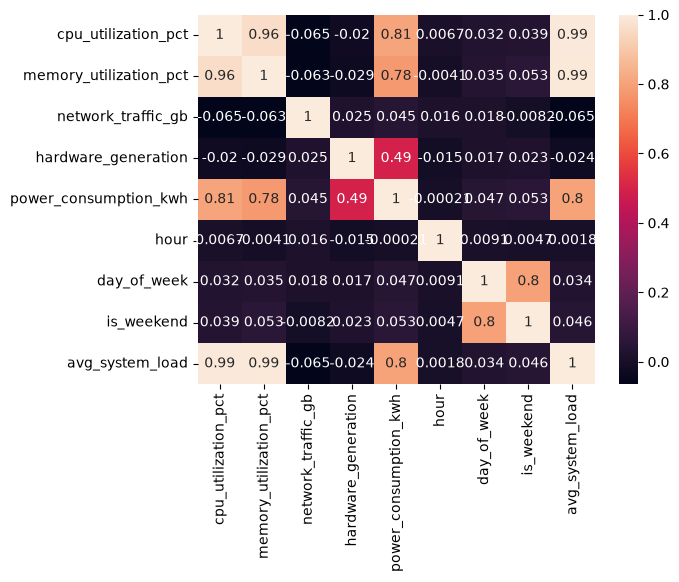

In [17]:
sns.heatmap(df.corr(),annot=True)

## vertical splitting 

In [18]:
X=df.drop(columns='power_consumption_kwh')
Y=df['power_consumption_kwh']

## train Test split

In [19]:
from sklearn.model_selection import train_test_split

In [20]:
xtrain,xtest,ytrain,ytest=train_test_split(X,Y,random_state=23)

## Scaling 

In [21]:
from sklearn.preprocessing import StandardScaler

In [22]:
ss=StandardScaler()
xtrain=pd.DataFrame(ss.fit_transform(xtrain))
xtest=pd.DataFrame(ss.transform(xtest))

## get the model 

In [23]:
from sklearn.linear_model import LinearRegression

In [24]:
model=LinearRegression()
model.fit(xtrain,ytrain)


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](8,)","[42.08, 0.15, 7.22,..., 1.09, 0.19,23.49]"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,153.1
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(7)
"singular_ singular_: array of shape (min(X, y),)Singular values of `X`. Only available when `X` is dense.","ndarray[float64](8,)","[57.22,44.49,33.48,...,14.84, 6.54, 0. ]"


## predicting both the train data and the target data to check the correctness

In [25]:
predictedTrain=model.predict(xtrain)
predictedTest=model.predict(xtest)

## Evaluation

In [26]:
from sklearn.metrics import mean_squared_error,mean_absolute_error,root_mean_squared_error

## of train data first 

In [27]:
print("Error of train data :-")
print('mean_squared_error:',mean_squared_error(ytrain,predictedTrain))
print('mean_absolute_error:',mean_absolute_error(ytrain,predictedTrain))
print('root_mean_squared_error:',root_mean_squared_error(ytrain,predictedTrain))

Error of train data :-
mean_squared_error: 504.13249680625495
mean_absolute_error: 16.127858751095637
root_mean_squared_error: 22.452895065141487


## OF test data 

In [28]:
print("Error of test data :-")
print('mean_squared_error:',mean_squared_error(ytest,predictedTest))
print('mean_absolute_error:',mean_absolute_error(ytest,predictedTest))
print('root_mean_squared_error:',root_mean_squared_error(ytest,predictedTest))

Error of test data :-
mean_squared_error: 504.08699923137084
mean_absolute_error: 15.880369158683088
root_mean_squared_error: 22.45188186391891


## R2 score will give us the accuracy in percentage 

In [29]:
from sklearn.metrics import r2_score
import pandas as pd

print(f"R² Score: {r2_score(ytest, predictedTest)*100:.2f} %")

# Extract feature importance (weights)
weights = pd.DataFrame({'Feature': X.columns, 'Impact_Weight': model.coef_})
print(weights.sort_values(by='Impact_Weight', ascending=False))


R² Score: 91.83 %
                  Feature  Impact_Weight
0     cpu_utilization_pct      42.080082
3     hardware_generation      40.531715
7         avg_system_load      23.488623
2      network_traffic_gb       7.221382
5             day_of_week       1.087671
6              is_weekend       0.192489
1  memory_utilization_pct       0.153987
4                    hour      -0.151842


### if i were in a real company i would need a single answer for the total power consumption . so i if treat the train part as previous month data and test part as the current month data then we can see waht the model is predicting and is it right or not.

In [30]:
# 1. predictedTest holds the predicted power for each individual log
# print("First 5 individual log predictions (kWh):", predictedTest[:])

# 2. Sum them up to get the TOTAL predicted power for the entire test period!
total_predicted_power = predictedTest.sum()
print(f"⚡ Total Predicted Power Consumption for xtest: {total_predicted_power:,.2f} kWh")

# 3. (Since we actually have y_test right now, we can verify how close our total was!)
total_actual_power = ytest.sum()
print(f"📊 Actual Power Consumption xtest:          {total_actual_power:,.2f} kWh")


⚡ Total Predicted Power Consumption for xtest: 58,756.58 kWh
📊 Actual Power Consumption xtest:          58,836.33 kWh
